# Role C 专题实验：Task 4（数据增强与固定损坏鲁棒性）、Challenge 2（CIFAR-10→STL-10 跨域泛化）、Task 6（统一 T4 成本与权衡）

本 Notebook 仅做**编排与展示**：所有训练、评测、画图逻辑都在 `lab1/src/run_role_c_experiments.py`（复用 `train.py` / `metrics.py` / `corruptions.py` / `plots.py`）中实现，这里不重复任何实现代码。

状态说明：smoke 检查与全部 5 个 30-epoch 正式训练已在 Tesla T4 上完成，不再重跑；本 Notebook 在 SSH 主机 `lix33@jade.org.aalto.fi` 上执行统一评测（Jade GPU：NVIDIA RTX 2000 Ada Generation，FP32）。

执行方式：在 Jade 上运行 `jupyter nbconvert --to notebook --execute lab1/notebooks/role_c_task4_challenge2_task6.ipynb --output role_c_task4_challenge2_task6_output.ipynb`，顺序执行全部 cell 并生成带输出的 `role_c_task4_challenge2_task6_output.ipynb` 作为实测记录。

## 固定路径与运行策略

- 仓库工作树：`REPO_DIR = /u/10/lix33/unix/ScalableMlLab`（Jade 上解压的当前工作树，不从 main 克隆或拉取——旧 main 可能不含本实现）。
- 持久工作目录：`WORK_LAB1 = /u/10/lix33/unix/ScalableMlLab/lab1`，其下 `data/`、`data_role_c/`、`checkpoints/`、`results_role_c/` 用于持久化，支持断点续跑；回收到仓库时 `results_role_c/` 仍映射为 `lab1/results/`。
- 断点续跑语义：runner 对每个 exp_id 做**完整校验**（history 恰为连续 epoch 1–30、结果 JSON 配置/seed/增强/T4 环境/`num_trained_samples=1,350,000` 一致、checkpoint 可实际加载且与 JSON/split stats 一致），全部通过才跳过训练；不完整记录自动重训，配置冲突则报错并保留原文件。
- 运行开关：smoke 与正式训练已完成，本次不重跑（`RUN_SMOKE=False`，`RUN_TRAINING=False`），仅执行统一评测（`RUN_EVALUATION=True`）；`evaluate` 在 5 行训练记录全部通过校验前拒绝访问 CIFAR-10 test / STL-10。

In [1]:
# 路径、依赖与运行开关（仅编排，无训练/评测/画图逻辑）
import sys
from pathlib import Path

REPO_DIR = Path("/u/10/lix33/unix/ScalableMlLab")
WORK_LAB1 = Path("/u/10/lix33/unix/ScalableMlLab/lab1")
SMOKE_WORK = Path("/u/10/lix33/unix/ScalableMlLab/lab1")  # 历史 smoke 占位，本次评测不使用

# 运行开关：smoke 与 5 个 30-epoch 训练已在 Tesla T4 上完成，不重跑；仅在 Jade 上执行评测
RUN_SMOKE = False
RUN_TRAINING = False
RUN_EVALUATION = True

sys.path.insert(0, str(REPO_DIR / "lab1" / "src"))

import torch
import pandas as pd
from IPython.display import Image, display

from run_role_c_experiments import (
    EXPERIMENT_SPECS,
    assert_jade_gpu,
    run_evaluation,
    run_smoke_stage,
    run_training_stage,
)

print(f"REPO_DIR  = {REPO_DIR}")
print(f"WORK_LAB1 = {WORK_LAB1}")

REPO_DIR  = /u/10/lix33/unix/ScalableMlLab
WORK_LAB1 = /u/10/lix33/unix/ScalableMlLab/lab1


/u/10/lix33/unix/ScalableMlLab/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 硬件断言

训练已在 Google Colab **Tesla T4** 上完成（训练 JSON 中的环境记录保留为 T4，不重跑）；本次统一评测在 SSH Jade 主机 **NVIDIA RTX 2000 Ada Generation** 上完成，runner 的评测 stage 内部也会再次断言该 GPU。

In [2]:
# 断言当前 CUDA 设备恰好为 Jade RTX 2000 Ada Generation
device = assert_jade_gpu()
device_name = torch.cuda.get_device_name(0)
print(f"CUDA device: {device_name}")
assert device_name == "NVIDIA RTX 2000 Ada Generation", f"评测要求 Jade RTX 2000 Ada Generation，当前为 {device_name}"

CUDA device: NVIDIA RTX 2000 Ada Generation


## Smoke 检查（历史记录，已在 T4 完成，本次不重跑）

历史 smoke：在 512 个 train ID、128 个 val ID 上跑 1 epoch 增强 ResNet（`evaluate_test=False`），使用独立 smoke 目录；绝不迭代或评测 CIFAR-10 test，也完全不加载 STL-10。以下 cell 仅保留为可选复现，`RUN_SMOKE=False` 下不执行。

In [3]:
# Smoke stage（历史可选复现，本次 RUN_SMOKE=False，不执行）
if RUN_SMOKE:
    smoke_record = run_smoke_stage(REPO_DIR, SMOKE_WORK, device)
    print("Smoke 完成，结果目录：", SMOKE_WORK / "results" / "smoke_role_c")
else:
    print("RUN_SMOKE=False，跳过 smoke（历史 smoke 已在 Tesla T4 上完成）")

RUN_SMOKE=False，跳过 smoke（历史 smoke 已在 Tesla T4 上完成）


## 正式训练（冻结的 5 行 T4 实验矩阵，已完成，不重跑）

训练矩阵固定（超参数来自 `lab1/configs/baseline.json`，SGD+momentum 0.9、weight_decay 5e-4、cosine、bs=128、30 epochs、FP32、1,350,000 trained samples），已全部在 Tesla T4 上完成：

| exp_id | task | model | seed | augmentation |
|---|---|---|---:|---|
| `t6_alexnet_cifar_no_aug_s42` | task6 | alexnet_cifar | 42 | none |
| `t4_resnet18_cifar_no_aug_s42` | task4 | resnet18_cifar | 42 | none |
| `t4_resnet18_cifar_crop_flip_s42` | task4 | resnet18_cifar | 42 | crop32_pad4_hflip05 |
| `t6_resnet18_cifar_crop_flip_s0` | task6 | resnet18_cifar | 0 | crop32_pad4_hflip05 |
| `t6_resnet18_cifar_crop_flip_s123` | task6 | resnet18_cifar | 123 | crop32_pad4_hflip05 |

以下 cell 仅保留为可选复现，`RUN_TRAINING=False` 下不执行；断点续跑由 runner 的 `validate_training_record` 完整校验决定（见上文“运行策略”）；训练阶段 `evaluate_test=False, run_benchmark=False`，不触碰 test/STL。训练成本口径为 T4。

In [4]:
# 正式训练 stage（历史可选复现，本次 RUN_TRAINING=False，不执行）
if RUN_TRAINING:
    train_report = run_training_stage(REPO_DIR, WORK_LAB1, device)
    print("训练 stage 完成：")
    for key, value in train_report.items():
        print(f"  {key}: {value}")
else:
    print("RUN_TRAINING=False，跳过正式训练（5 个 30-epoch 训练已在 Tesla T4 上完成）")

RUN_TRAINING=False，跳过正式训练（5 个 30-epoch 训练已在 Tesla T4 上完成）


## 统一评测（Task 4 / Challenge 2 / Task 6，在 Jade 上执行）

评测 stage 先校验 5 份 T4 训练记录齐全有效，再加载冻结损坏配置 `lab1/configs/corruptions_t4.json`（seed=2223，image_ids 0–9999，rotation_15deg / translation_3px / gaussian_noise_std_0_05），对 5 个 checkpoint 在 Jade RTX 2000 Ada Generation 上统一完成：

- **Task 4**：clean + 三种固定损坏的 accuracy/CE/macro-F1、accuracy drop、prediction flip rate、clean-correct→wrong 统计与评测耗时；
- **Challenge 2**：CIFAR shared-9、STL-10 双口径（10-way / masked 9-way）、frog leakage、domain drop 与逐类 drop；
- **Task 6**：bs=1 延迟、bs=128 吞吐（warmup=10 / measured=50，Jade 口径）、seed 敏感性、训练时长敏感性、与角色 A RTX 5070 Ti 记录的硬件对照（仅并列展示灵敏度，非同硬件性能对比）。

逐图预测写入 `results_role_c/predictions/<exp_id>.npz`（回收到仓库 `results/predictions/`），结果 JSON 原子更新，角色 C 专用 CSV 与全部图表由 runner 生成。STL-10 缓存在独立可写的 `data_role_c/`。训练成本口径为 T4，推理成本口径为 Jade。

In [5]:
# 统一评测 stage：Task 4 + Challenge 2 + Task 6（Jade RTX 2000 Ada Generation，FP32）
if RUN_EVALUATION:
    records = run_evaluation(REPO_DIR, WORK_LAB1, device)
    print(f"评测完成，共更新 {len(records)} 份结果 JSON")
else:
    print("RUN_EVALUATION=False，跳过统一评测")


>>> Evaluating t6_alexnet_cifar_no_aug_s42 (alexnet_cifar, device=cuda:0) ...


<<< t6_alexnet_cifar_no_aug_s42: clean=0.8266, mean_corrupted=0.7207, stl9=0.6825, domain_drop=0.1485, bs1=0.309ms

>>> Evaluating t4_resnet18_cifar_no_aug_s42 (resnet18_cifar, device=cuda:0) ...


<<< t4_resnet18_cifar_no_aug_s42: clean=0.8658, mean_corrupted=0.7609, stl9=0.7267, domain_drop=0.1417, bs1=0.906ms

>>> Evaluating t4_resnet18_cifar_crop_flip_s42 (resnet18_cifar, device=cuda:0) ...


<<< t4_resnet18_cifar_crop_flip_s42: clean=0.9308, mean_corrupted=0.8322, stl9=0.8108, domain_drop=0.1231, bs1=0.914ms

>>> Evaluating t6_resnet18_cifar_crop_flip_s0 (resnet18_cifar, device=cuda:0) ...


<<< t6_resnet18_cifar_crop_flip_s0: clean=0.9279, mean_corrupted=0.8253, stl9=0.8128, domain_drop=0.1156, bs1=0.852ms

>>> Evaluating t6_resnet18_cifar_crop_flip_s123 (resnet18_cifar, device=cuda:0) ...


<<< t6_resnet18_cifar_crop_flip_s123: clean=0.9292, mean_corrupted=0.8221, stl9=0.8093, domain_drop=0.1219, bs1=0.849ms

Role C evaluation complete: 5 records updated, CSV tables in /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c.


Role C figures written to /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures:
  t4_learning_curves.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/t4_learning_curves.png
  t4_corruption_accuracy.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/t4_corruption_accuracy.png
  t4_per_class_drops.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/t4_per_class_drops.png
  t4_corruption_examples.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/t4_corruption_examples.png
  challenge2_domain_drop.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/challenge2_domain_drop.png
  challenge2_stl10_confusion.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/challenge2_stl10_confusion.png
  challenge2_stl10_failures.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/challenge2_stl10_failures.png
  t6_tradeoffs.png -> /u/10/lix33/unix/ScalableMlLab/lab1/results_role_c/figures/t6_tradeo

## 结果表格

直接读取 runner 生成的角色 C 专用 CSV（不修改团队 `summary.csv`）。

In [6]:
# 展示角色 C 汇总表与 Task 6 三份专项表
RESULTS_DIR = WORK_LAB1 / "results_role_c"

csv_files = [
    "role_c_summary.csv",
    "task6_seed_sensitivity.csv",
    "task6_training_duration.csv",
    "task6_hardware_comparison.csv",
]
for name in csv_files:
    path = RESULTS_DIR / name
    print(f"=== {name} ===")
    display(pd.read_csv(path))

=== role_c_summary.csv ===


,exp_id,task,model,seed,augmentation,device_name,training_device_name,inference_device_name,total_params,best_epoch,...,mean_corrupted_acc,stl10_10way_acc,stl10_9way_masked_acc,stl10_frog_leakage_rate,domain_drop_9way,total_train_time_sec,peak_gpu_mem_mb,bs1_latency_ms,bs128_latency_ms_per_batch,bs128_throughput_imgs_per_sec
0,t6_alexnet_cifar_no_aug_s42,task6,alexnet_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,6976842,28,...,0.720667,0.667500,0.682500,0.031389,0.148500,353.666,316.91,0.308709,4.496393,28467.264682
1,t4_resnet18_cifar_no_aug_s42,task4,resnet18_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,28,...,0.760900,0.710694,0.726667,0.035139,0.141667,1855.352,802.99,0.905939,16.795464,7621.105181
2,t4_resnet18_cifar_crop_flip_s42,task4,resnet18_cifar,42,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.832200,0.801389,0.810833,0.018472,0.123056,1859.826,802.99,0.914313,16.856545,7593.489759
3,t6_resnet18_cifar_crop_flip_s0,task6,resnet18_cifar,0,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,30,...,0.825300,0.800972,0.812778,0.023889,0.115556,1858.514,802.99,0.852418,16.898406,7574.679098
4,t6_resnet18_cifar_crop_flip_s123,task6,resnet18_cifar,123,crop32_pad4_hflip05,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,11173962,29,...,0.822100,0.799306,0.809306,0.018889,0.121917,1856.025,802.99,0.849120,16.892198,7577.462514


=== task6_seed_sensitivity.csv ===


,metric,mean,sample_std,min,max
0,best_val_acc,0.931400,0.001908,0.930200,0.933600
1,clean_test_acc,0.929300,0.001453,0.927900,0.930800
2,rotation_15deg_acc,0.882300,0.004176,0.879500,0.887100
3,translation_3px_acc,0.926133,0.001710,0.925000,0.928100
4,gaussian_noise_std_0_05_acc,0.671167,0.009962,0.661500,0.681400
5,mean_corrupted_acc,0.826533,0.005162,0.822100,0.832200
6,stl10_9way_masked_acc,0.810972,0.001740,0.809306,0.812778
7,domain_drop_9way,0.120176,0.004042,0.115556,0.123056
8,total_train_time_sec,1858.121667,1.930633,1856.025000,1859.826000


=== task6_training_duration.csv ===


,exp_id,model,seed,augmentation,epoch,val_acc,cumulative_train_time_sec
0,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,42,none,10,0.8046,112.300796
1,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,42,none,20,0.8236,233.422015
2,t6_alexnet_cifar_no_aug_s42,alexnet_cifar,42,none,30,0.8294,353.633997
3,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,42,none,10,0.8048,620.370612
4,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,42,none,20,0.8712,1237.622316
5,t4_resnet18_cifar_no_aug_s42,resnet18_cifar,42,none,30,0.8734,1855.161050
6,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,42,crop32_pad4_hflip05,10,0.7854,622.241989
7,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,42,crop32_pad4_hflip05,20,0.8832,1241.473428
8,t4_resnet18_cifar_crop_flip_s42,resnet18_cifar,42,crop32_pad4_hflip05,30,0.9304,1859.618124
9,t6_resnet18_cifar_crop_flip_s0,resnet18_cifar,0,crop32_pad4_hflip05,10,0.7956,621.131254


=== task6_hardware_comparison.csv ===


,comparison_pair,exp_id,owner,model,seed,augmentation,device_name,training_device_name,inference_device_name,total_train_time_sec,bs1_latency_ms,bs128_throughput_imgs_per_sec,clean_test_acc,comparison_note
0,alexnet_cifar,t2_alexnet_cifar_baseline_s42,role_a,alexnet_cifar,42,none,NVIDIA GeForce RTX 5070 Ti Laptop GPU,NVIDIA GeForce RTX 5070 Ti Laptop GPU,NVIDIA GeForce RTX 5070 Ti Laptop GPU,248.240,3.059050,41853.673019,0.8214,different hardware (RTX 5070 Ti vs Tesla T4); ...
1,alexnet_cifar,t6_alexnet_cifar_no_aug_s42,role_c,alexnet_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,353.666,0.308709,28467.264682,0.8266,different hardware (RTX 5070 Ti vs Tesla T4); ...
2,resnet18_cifar,t2_resnet18_cifar_baseline_s42,role_a,resnet18_cifar,42,none,NVIDIA GeForce RTX 5070 Ti Laptop GPU,NVIDIA GeForce RTX 5070 Ti Laptop GPU,NVIDIA GeForce RTX 5070 Ti Laptop GPU,684.971,11.627854,11404.723338,0.8701,different hardware (RTX 5070 Ti vs Tesla T4); ...
3,resnet18_cifar,t4_resnet18_cifar_no_aug_s42,role_c,resnet18_cifar,42,none,Tesla T4,Tesla T4,NVIDIA RTX 2000 Ada Generation,1855.352,0.905939,7621.105181,0.8658,different hardware (RTX 5070 Ti vs Tesla T4); ...


## 图表（9 张）

全部图表由 runner 在评测阶段基于已保存的 JSON/CSV/NPZ 生成，原始像素按 ID 从 CIFAR-10/STL-10 数据集重建、CIFAR 损坏图按同一冻结配置重建；此处仅展示，不重复造图逻辑。

--- t4_learning_curves.png ---


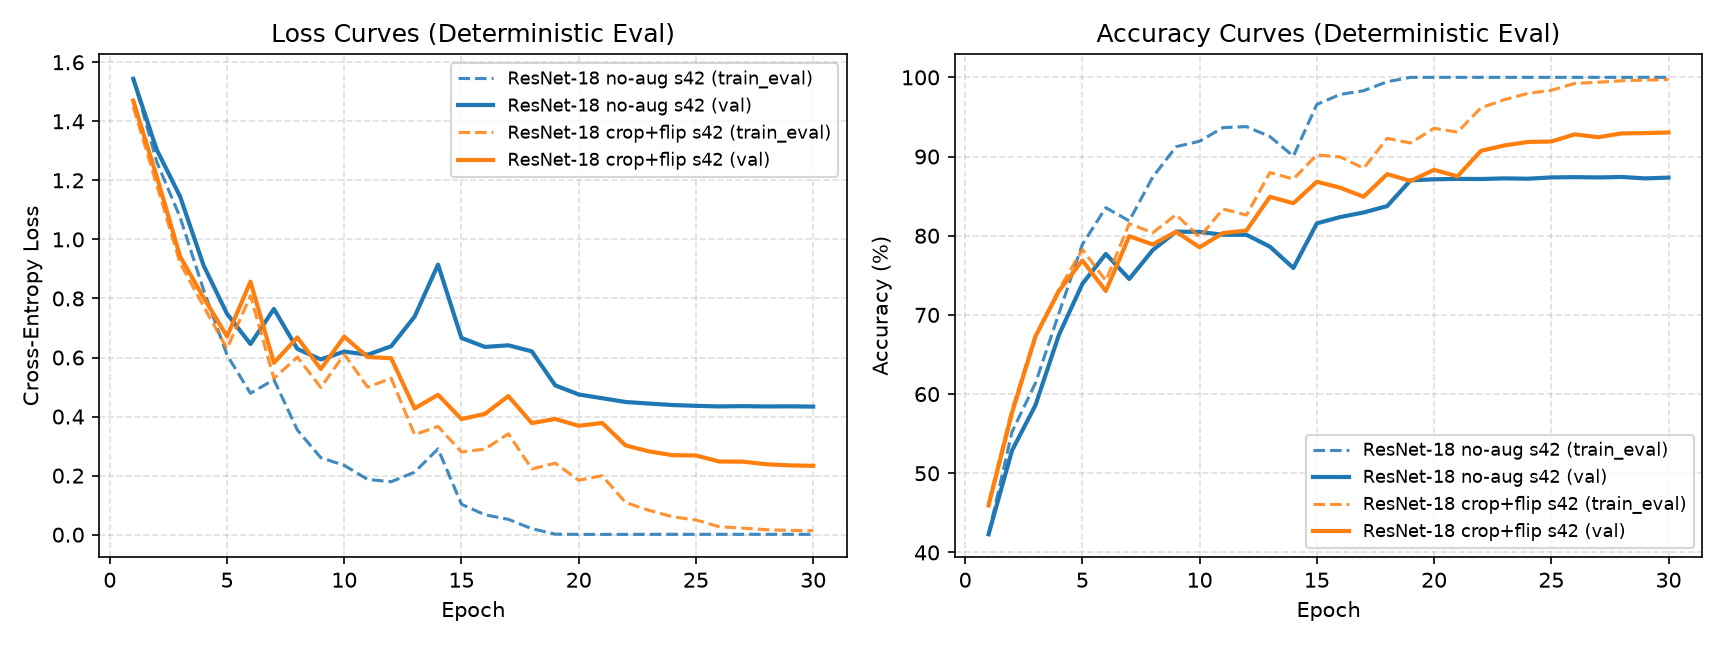

--- t4_corruption_accuracy.png ---


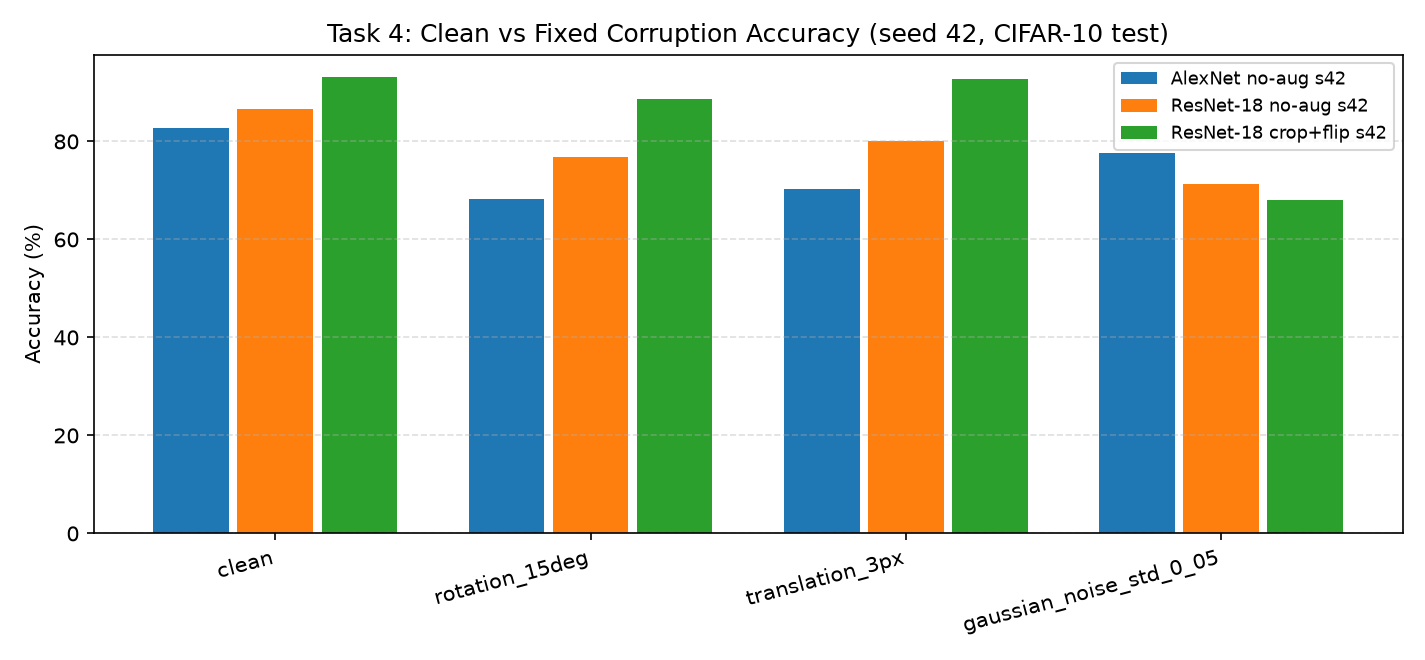

--- t4_per_class_drops.png ---


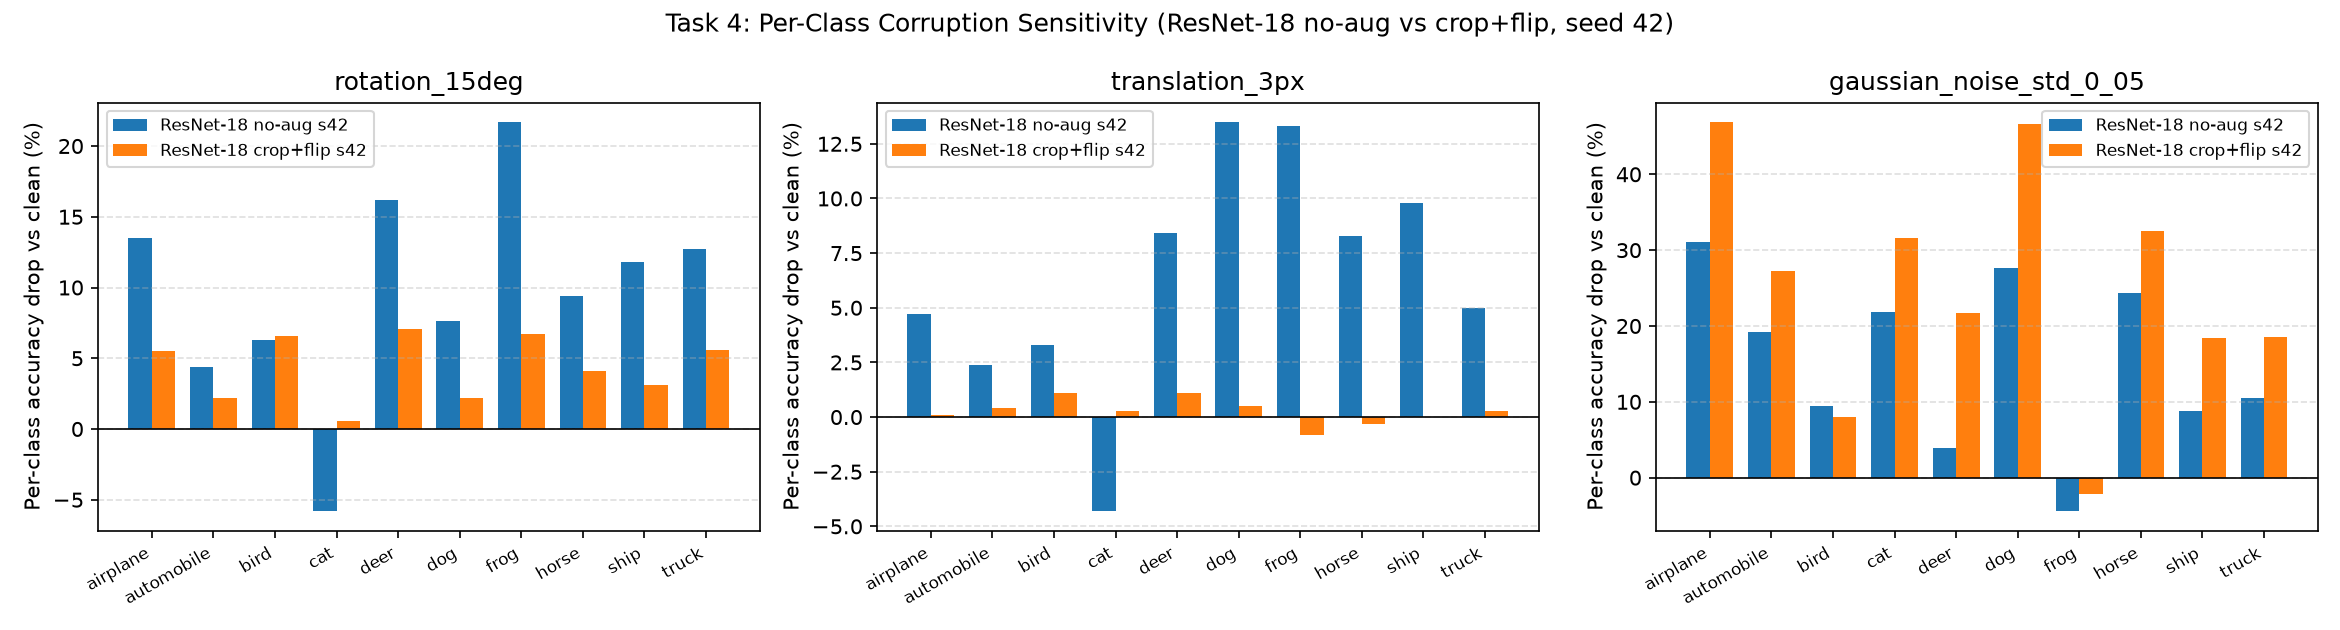

--- t4_corruption_examples.png ---


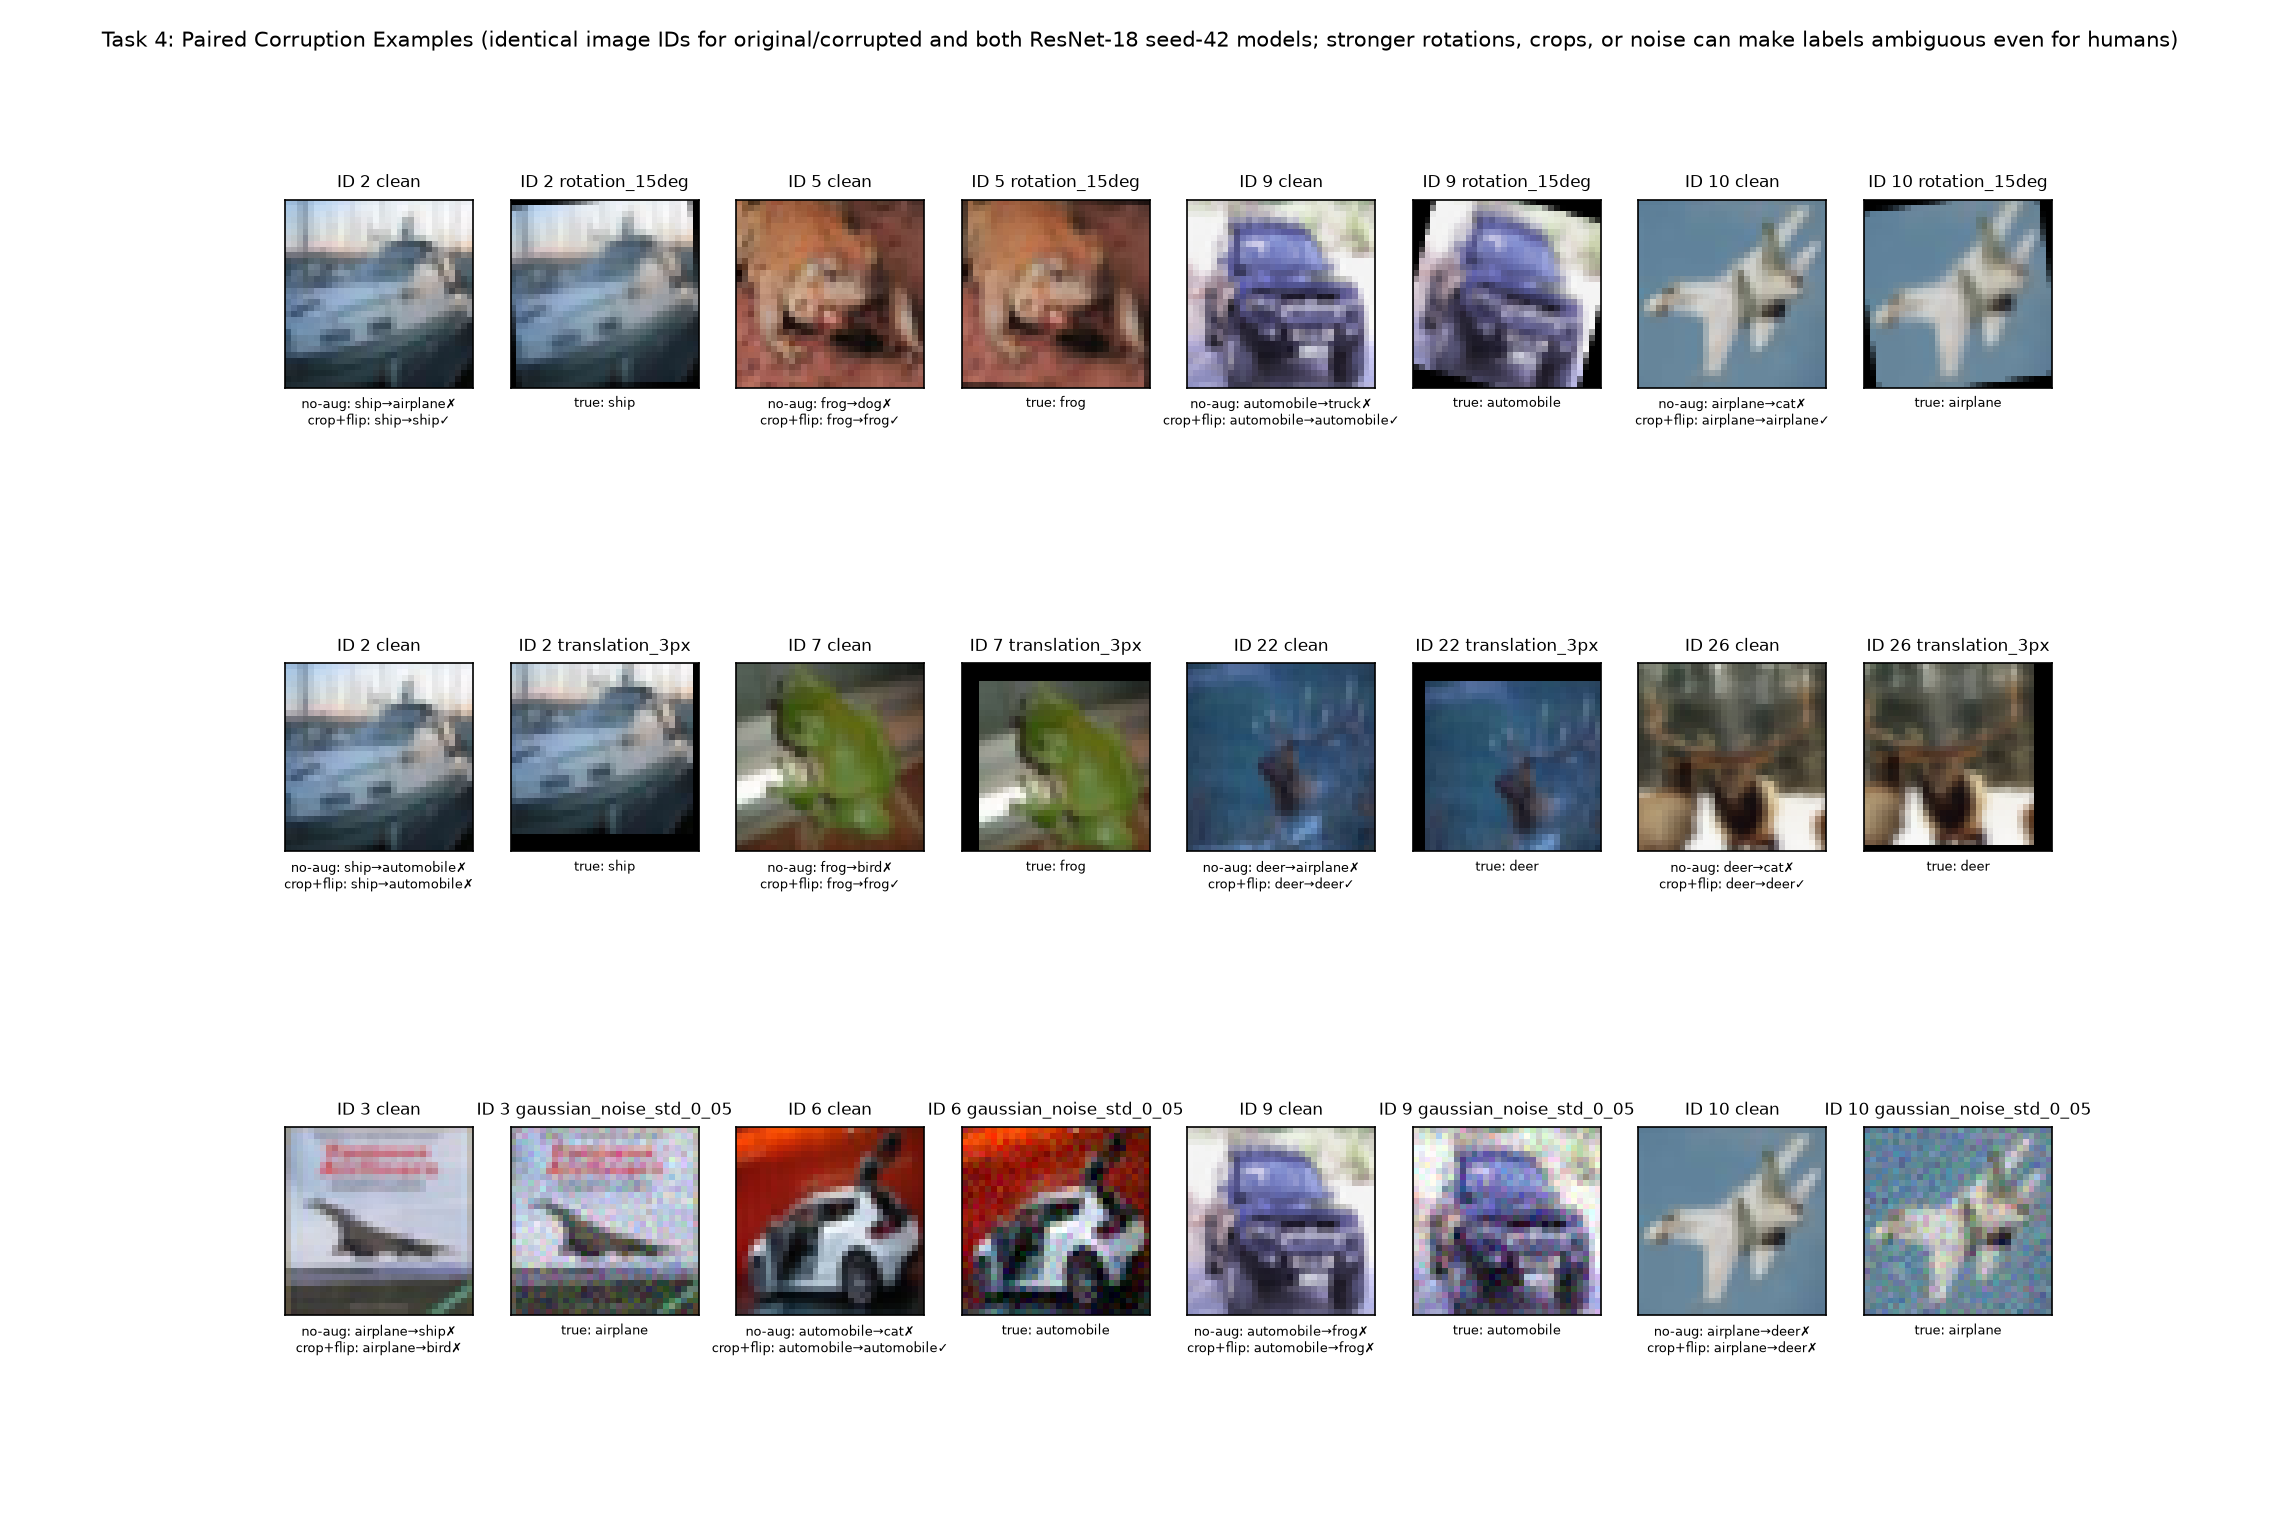

--- challenge2_domain_drop.png ---


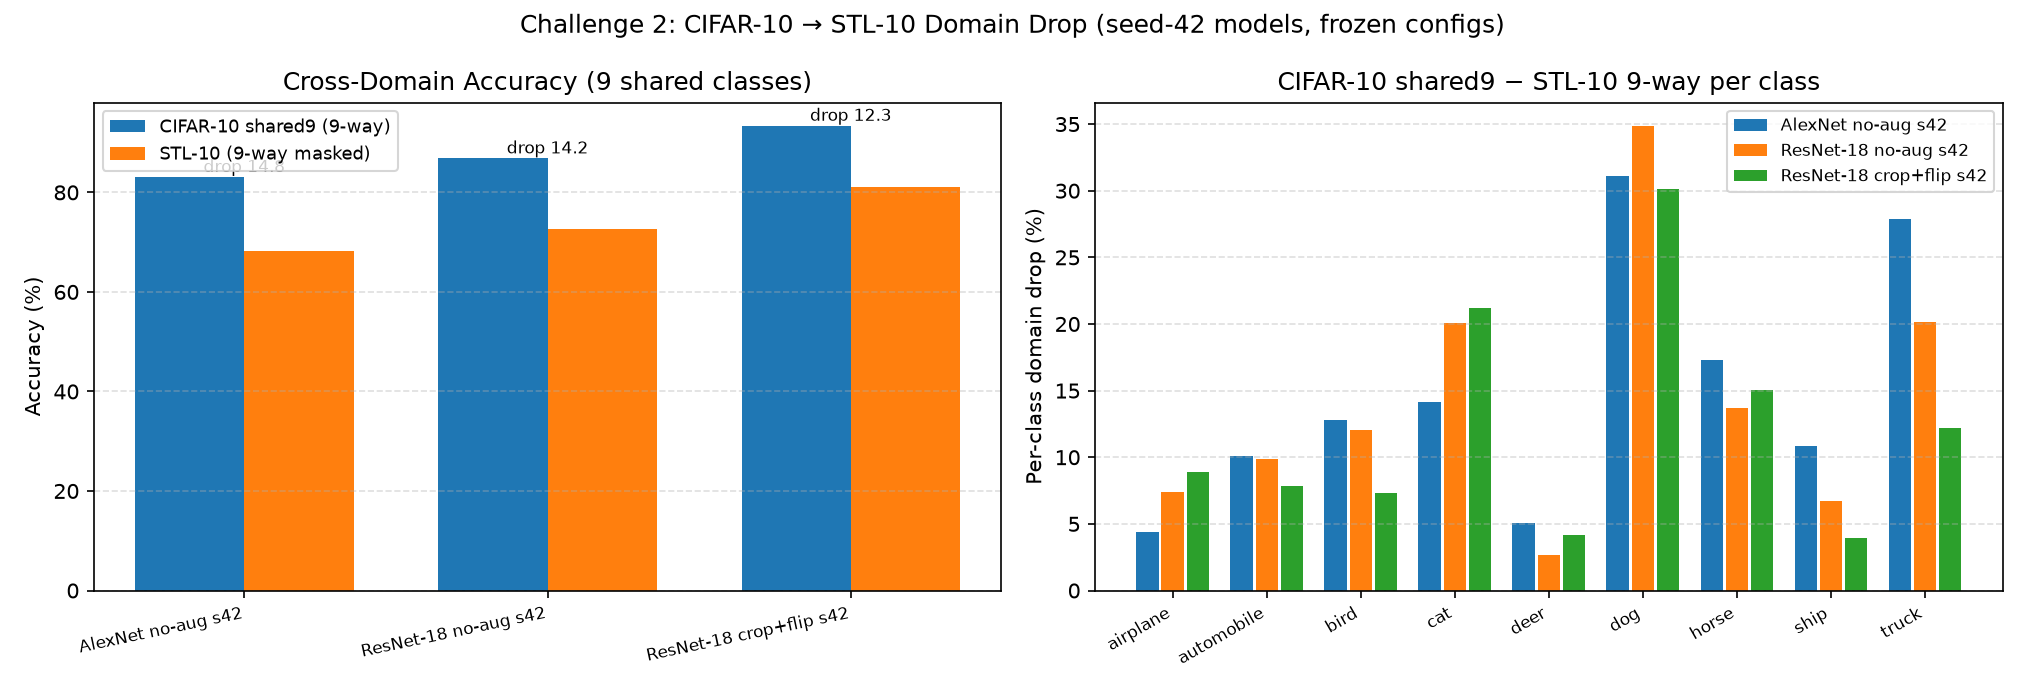

--- challenge2_stl10_confusion.png ---


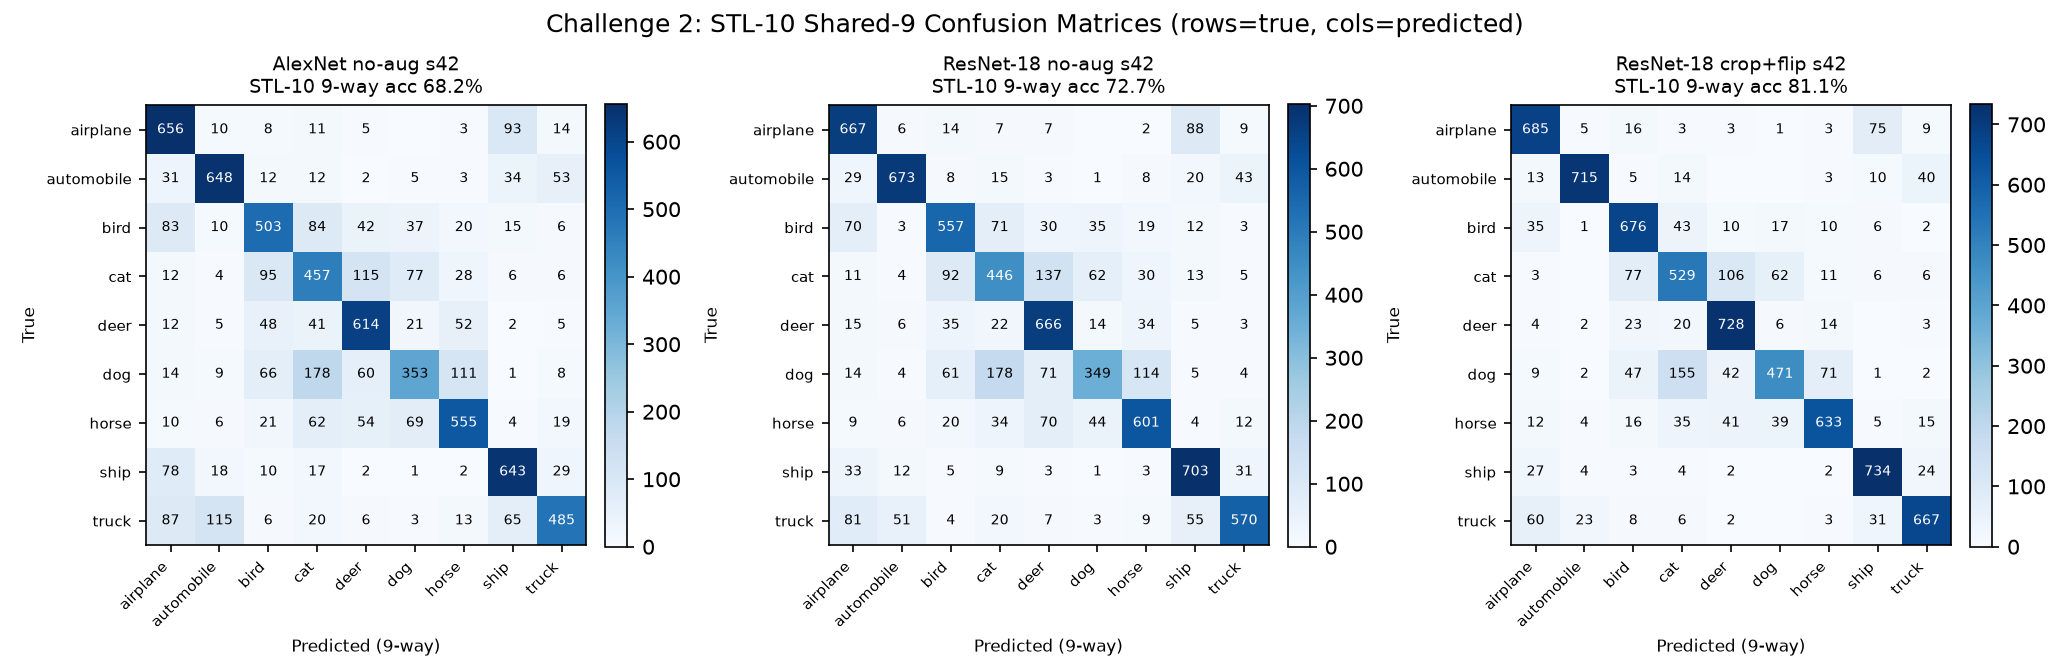

--- challenge2_stl10_failures.png ---


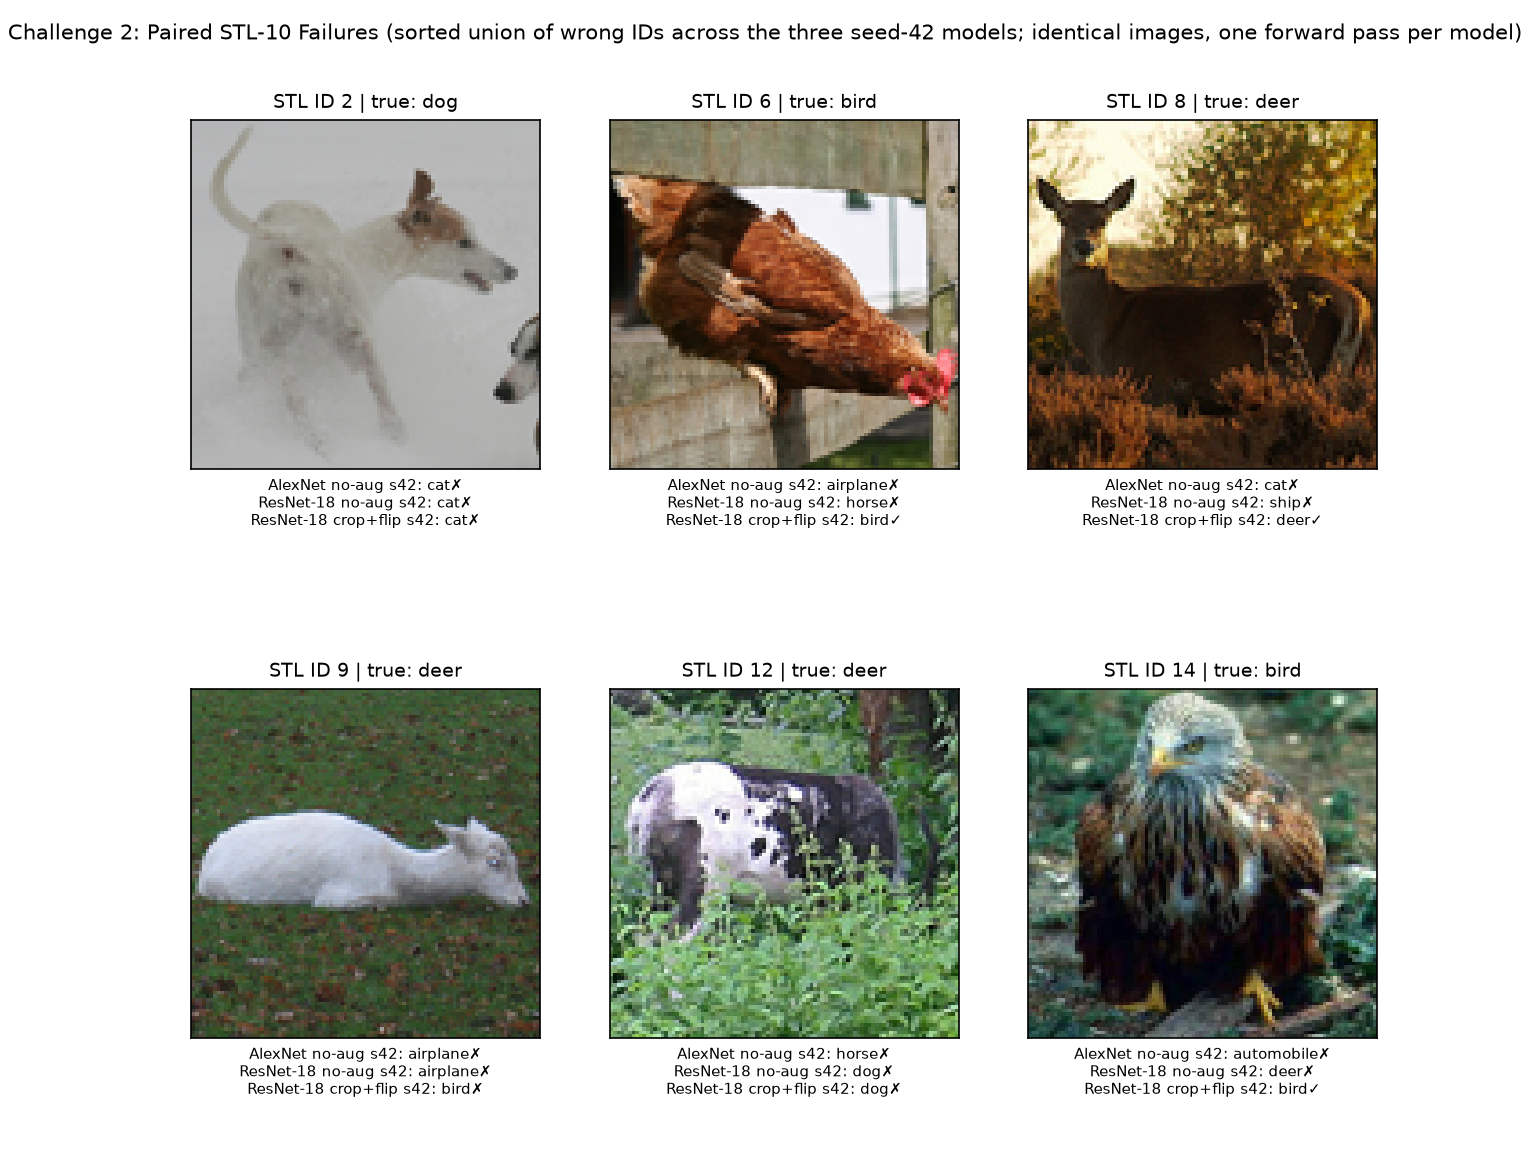

--- t6_tradeoffs.png ---


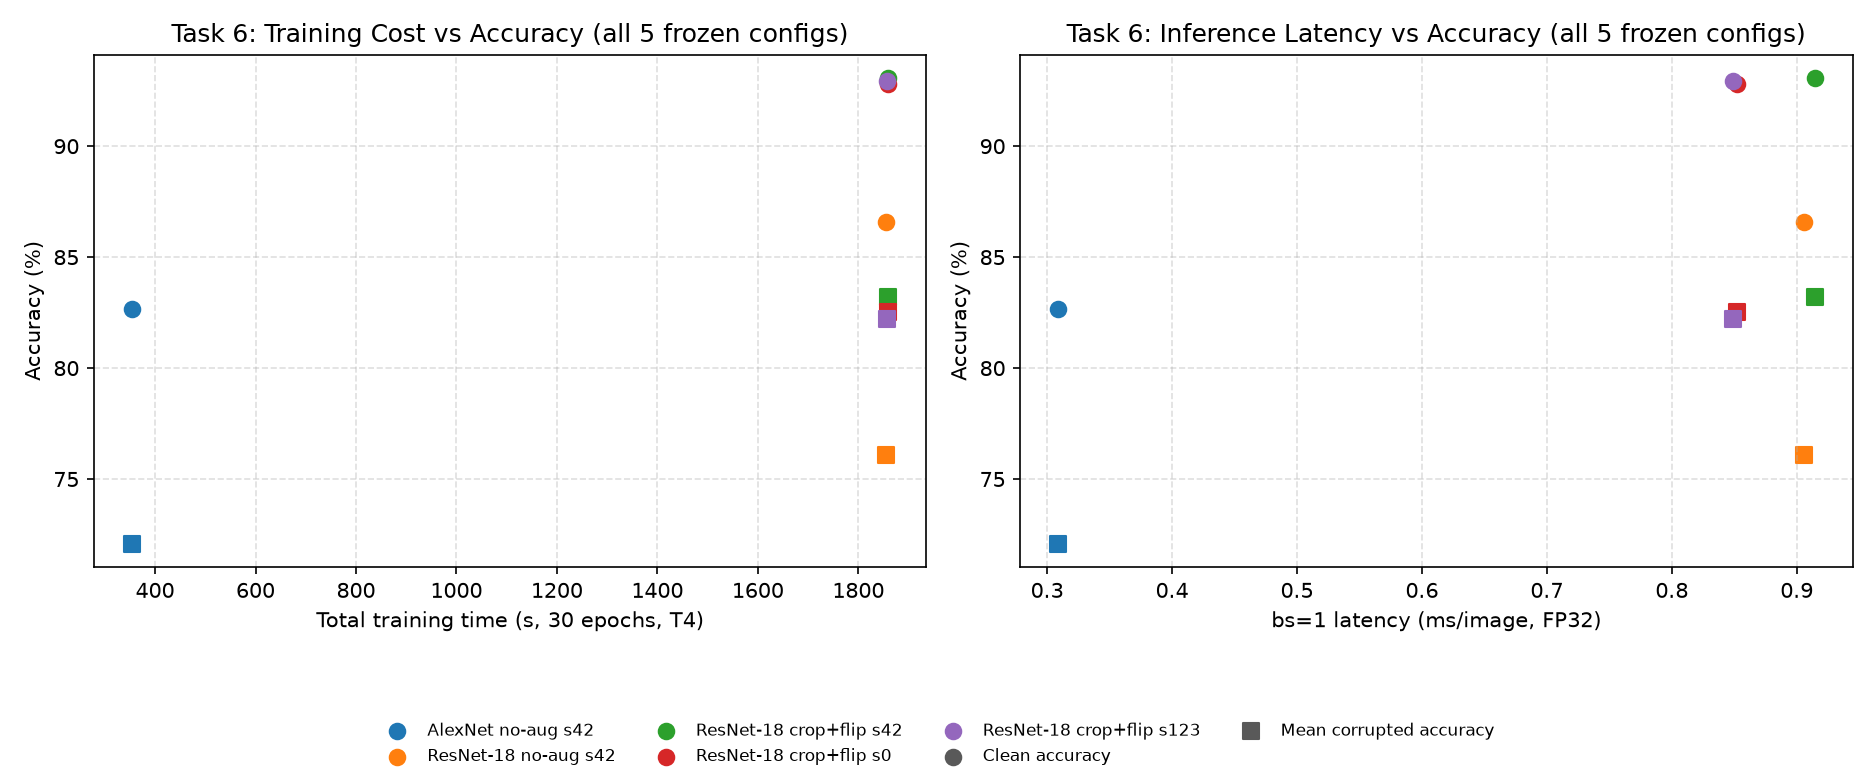

--- t6_training_duration.png ---


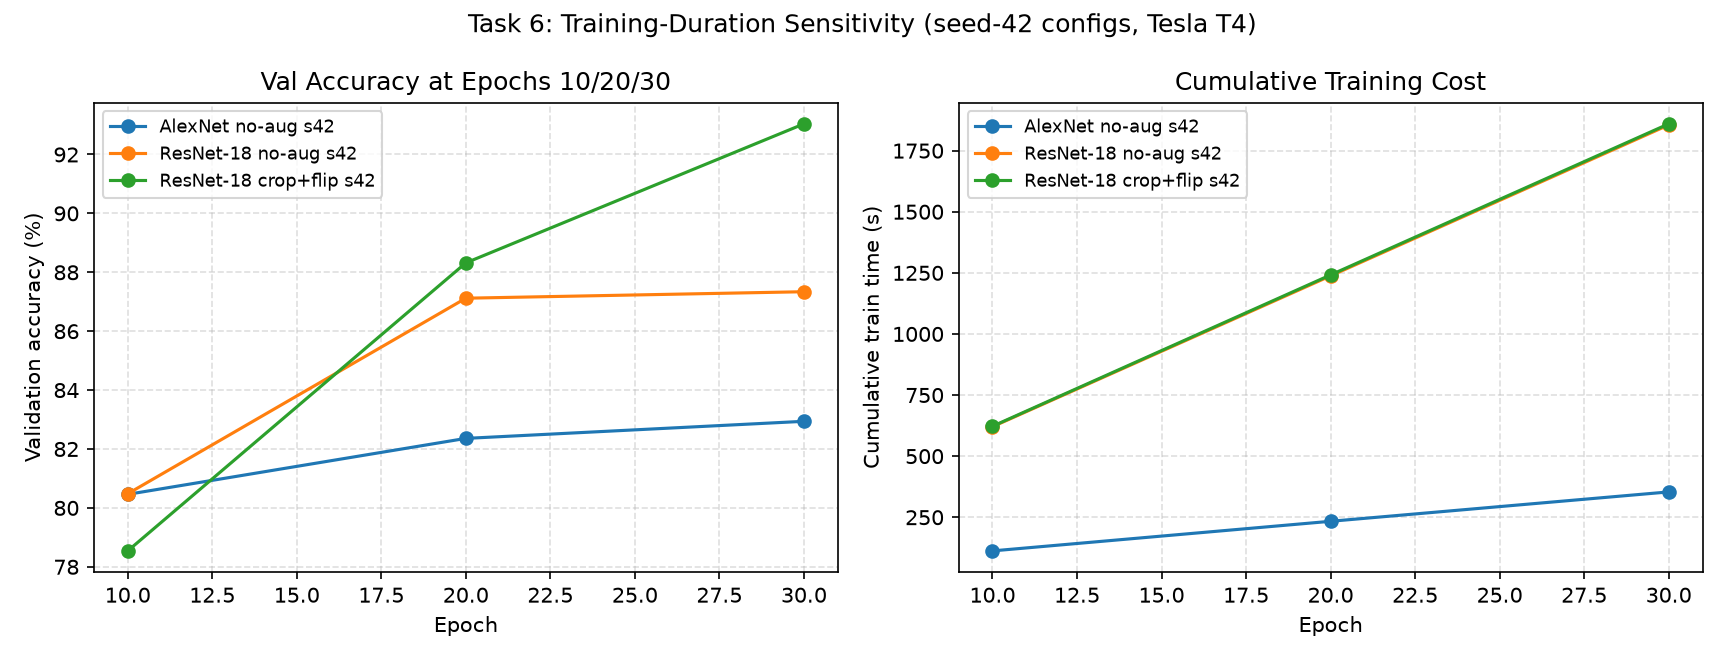

In [7]:
# 展示 results_role_c/figures 下全部 9 张 Role C 图
FIGURES_DIR = RESULTS_DIR / "figures"

figure_names = [
    "t4_learning_curves.png",
    "t4_corruption_accuracy.png",
    "t4_per_class_drops.png",
    "t4_corruption_examples.png",
    "challenge2_domain_drop.png",
    "challenge2_stl10_confusion.png",
    "challenge2_stl10_failures.png",
    "t6_tradeoffs.png",
    "t6_training_duration.png",
]
for name in figure_names:
    path = FIGURES_DIR / name
    assert path.is_file() and path.stat().st_size > 0, f"缺少图表: {path}"
    print(f"--- {name} ---")
    display(Image(filename=str(path)))

## Checkpoint 路径

5 个 `best.pt`（best-val checkpoint，位于 `WORK_LAB1/checkpoints/<exp_id>/best.pt`），供复核与后续使用。

In [8]:
# 打印 5 个 best.pt 路径并确认文件非空
for spec in EXPERIMENT_SPECS:
    ckpt = WORK_LAB1 / "checkpoints" / spec["exp_id"] / "best.pt"
    size = ckpt.stat().st_size
    assert size > 0, f"checkpoint 缺失或为空: {ckpt}"
    print(f"{spec['exp_id']:<38s} {ckpt}  ({size / 1e6:.1f} MB)")

t6_alexnet_cifar_no_aug_s42            /u/10/lix33/unix/ScalableMlLab/lab1/checkpoints/t6_alexnet_cifar_no_aug_s42/best.pt  (27.9 MB)
t4_resnet18_cifar_no_aug_s42           /u/10/lix33/unix/ScalableMlLab/lab1/checkpoints/t4_resnet18_cifar_no_aug_s42/best.pt  (44.8 MB)
t4_resnet18_cifar_crop_flip_s42        /u/10/lix33/unix/ScalableMlLab/lab1/checkpoints/t4_resnet18_cifar_crop_flip_s42/best.pt  (44.8 MB)
t6_resnet18_cifar_crop_flip_s0         /u/10/lix33/unix/ScalableMlLab/lab1/checkpoints/t6_resnet18_cifar_crop_flip_s0/best.pt  (44.8 MB)
t6_resnet18_cifar_crop_flip_s123       /u/10/lix33/unix/ScalableMlLab/lab1/checkpoints/t6_resnet18_cifar_crop_flip_s123/best.pt  (44.8 MB)


## 复现引用

- 数据集：[CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html)（50,000 train / 10,000 test，固定 split 见 `lab1/configs/split_indices.json`）；[STL-10](https://cs.stanford.edu/~acoates/stl10/)（7,200 test，仅取与 CIFAR-10 兼容的共享 9 类做跨域泛化）。
- 课程材料：本地 `lab1/notebooks/ID2223_Lab_Session_2.ipynb` 的 **Part A9**（本专题实验的原始要求）。
- 作业文档：课程 Lab 2 作业说明（Task 4 / Challenge 2 / Task 6 口径与交付要求）。
- 固定损坏协议：`lab1/configs/corruptions_t4.json`（version=1，seed=2223，rotation_15deg / translation_3px / gaussian_noise_std_0_05，image_ids 0–9999）。
- 执行环境：SSH 主机 `lix33@jade.org.aalto.fi`（评测 GPU 为 NVIDIA RTX 2000 Ada Generation，FP32）；训练在 Tesla T4 上完成，Notebook 评测经 `jupyter nbconvert --to notebook --execute` 在 Jade 上执行生成带输出版本。
- 成本口径：训练成本为 T4，推理成本为 Jade；角色 A RTX 5070 Ti 记录仅用于硬件敏感性并列对照。
- 实现入口：`lab1/src/run_role_c_experiments.py`（冻结 5 行矩阵、T4/Jade 断言、完整校验断点续跑、train→evaluate 隔离）。